In [23]:

import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent
sys.path.append(str(ROOT))

from src.sleep_probability import (
    add_sleep_features,
    analyze_sleep_compensation,
    analyze_night_owls,
    compensation_by_group,
    night_owls_by_group,
    weighted_sleep_statistics,
    save_results
)

DATA_PATH = ROOT / "data" / "final_dataset.csv"
OUTPUT_PATH = ROOT / "outputs"

sns.set_theme(style="whitegrid")


In [24]:

df = pd.read_csv(DATA_PATH)

df = add_sleep_features(df)

print("Dataset shape:", df.shape)
print("Total sample:", len(df))
print("Total survey weight:", df["WTINT2YR"].sum())

display(df.head())


Dataset shape: (1609, 14)
Total sample: 1609
Total survey weight: 68809274.98330599


,SEQN,INDFMPIR,WTINT2YR,RIDAGEYR,RIAGENDR,DMDEDUC2,INQ300,SLQ300,SLQ310,SLQ320,SLQ330,Weekday_Sleep,Weekend_Sleep,Sleep_Midpoint
0,130386.0,1.33,30995.282610,34.0,Male,4.0,2.0,0,450,0,480,7.5,8.0,4.00
1,130388.0,0.81,22234.443573,27.0,Female,4.0,2.0,1260,390,1380,540,9.5,10.0,4.00
2,130390.0,2.16,36895.283578,31.0,Female,3.0,2.0,1320,360,0,480,8.0,8.0,4.00
3,130391.0,0.93,45423.073281,33.0,Female,3.0,2.0,180,630,180,630,7.5,7.5,6.75
4,130395.0,1.10,18277.659785,33.0,Female,3.0,2.0,0,450,60,540,7.5,8.0,5.00


In [25]:

sleep_stats = weighted_sleep_statistics(df)

display(sleep_stats)


,Variable,Weighted Mean,Weighted Variance,Weighted Std,N
0,Weekday_Sleep,7.831072,2.113808,1.453894,1609
1,Weekend_Sleep,8.661823,2.479615,1.574679,1609


In [26]:

compensation = analyze_sleep_compensation(df)

display(compensation["summary"])


,Metric,Value
0,Valid sample size,1.609000e+03
1,Total survey weight,6.880927e+07
2,Weighted weekday mean,7.831072e+00
3,Weighted weekend mean,8.661823e+00
4,Event A threshold,6.831072e+00
5,Event B threshold,9.661823e+00
6,N(A),3.220000e+02
7,N(B),3.890000e+02
8,N(A intersection B),5.600000e+01
9,Weighted P(A),1.876061e-01


In [27]:

compensation = analyze_sleep_compensation(df)

display(compensation["summary"])


,Metric,Value
0,Valid sample size,1.609000e+03
1,Total survey weight,6.880927e+07
2,Weighted weekday mean,7.831072e+00
3,Weighted weekend mean,8.661823e+00
4,Event A threshold,6.831072e+00
5,Event B threshold,9.661823e+00
6,N(A),3.220000e+02
7,N(B),3.890000e+02
8,N(A intersection B),5.600000e+01
9,Weighted P(A),1.876061e-01


In [28]:

gender_compensation = compensation_by_group(
    df,
    "RIAGENDR"
)

education_compensation = compensation_by_group(
    df,
    "DMDEDUC2"
)

display(gender_compensation)
display(education_compensation)


,Group,N,Weighted P(A),Weighted P(B | A)
0,Female,896,0.160041,0.173542
1,Male,713,0.215187,0.226455


,Group,N,Weighted P(A),Weighted P(B | A)
0,1.0,25,0.155629,0.748234
1,2.0,116,0.203862,0.414096
2,3.0,378,0.212311,0.212614
3,4.0,532,0.217657,0.134566
4,5.0,557,0.138902,0.211505


In [29]:

night_owls = analyze_night_owls(df)

display(night_owls["summary"])


,Metric,Value
0,Valid sample size,1609.000000
1,Night Owl sample count,570.000000
2,Night Owl threshold,5.000000
3,Weighted Night Owl probability,0.364500
4,Weighted Night Owl percentage,36.450002


In [30]:

gender_owls = night_owls_by_group(
    df,
    "RIAGENDR"
)

education_owls = night_owls_by_group(
    df,
    "DMDEDUC2"
)

display(gender_owls)
display(education_owls)


,Group,N,Weighted Probability,Weighted Percentage
0,Female,896,0.833613,83.361323
1,Male,713,0.852810,85.280954


,Group,N,Weighted Probability,Weighted Percentage
0,1.0,25,0.817447,81.744665
1,2.0,116,0.932371,93.237097
2,3.0,378,0.843041,84.304063
3,4.0,532,0.864677,86.467713
4,5.0,557,0.809990,80.998967


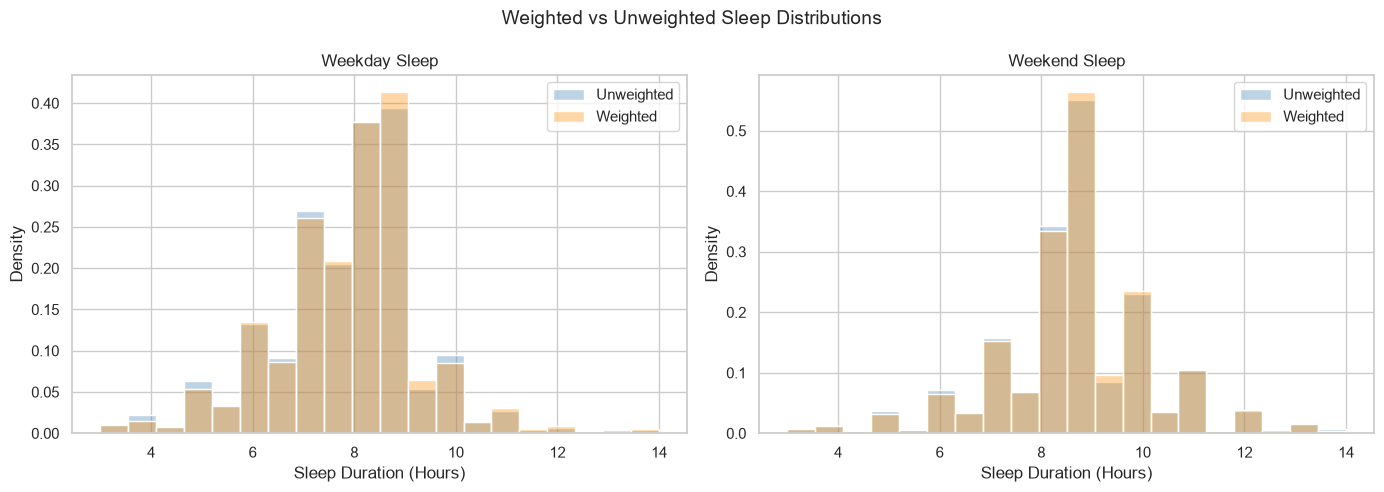

In [31]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Weekday Sleep
sns.histplot(
    data=df,
    x="Weekday_Sleep",
    bins=20,
    stat="density",
    color="steelblue",
    alpha=0.35,
    label="Unweighted",
    ax=axes[0]
)

sns.histplot(
    data=df,
    x="Weekday_Sleep",
    weights="WTINT2YR",
    bins=20,
    stat="density",
    color="darkorange",
    alpha=0.35,
    label="Weighted",
    ax=axes[0]
)

# Weekend Sleep
sns.histplot(
    data=df,
    x="Weekend_Sleep",
    bins=20,
    stat="density",
    color="steelblue",
    alpha=0.35,
    label="Unweighted",
    ax=axes[1]
)

sns.histplot(
    data=df,
    x="Weekend_Sleep",
    weights="WTINT2YR",
    bins=20,
    stat="density",
    color="darkorange",
    alpha=0.35,
    label="Weighted",
    ax=axes[1]
)

axes[0].set_title("Weekday Sleep")
axes[1].set_title("Weekend Sleep")

for ax in axes:
    ax.set_xlabel("Sleep Duration (Hours)")
    ax.set_ylabel("Density")
    ax.legend()

plt.suptitle("Weighted vs Unweighted Sleep Distributions", fontsize=14)
plt.tight_layout()
plt.show()


چرا انقدر کم شد اختلاف؟ بررسی کنیم ببینیم آیا وزن ها با طول مدت خواب رابطه ای داره؟

,WTINT2YR,Weekday_Sleep,Weekend_Sleep
WTINT2YR,1.000,0.072,0.040
Weekday_Sleep,0.072,1.000,0.408
Weekend_Sleep,0.040,0.408,1.000


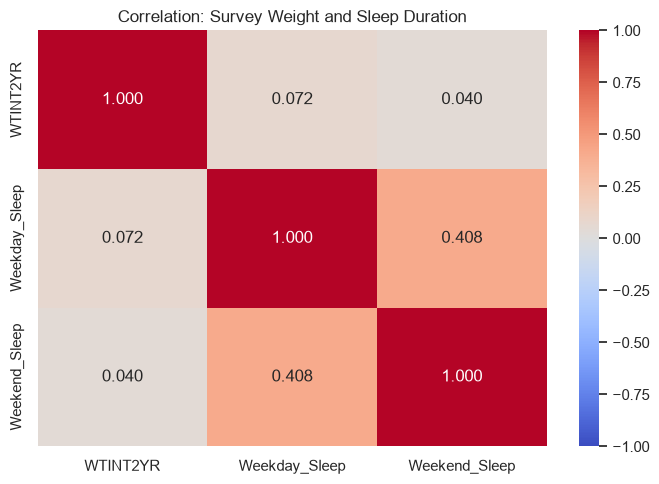

In [32]:
cols = ["WTINT2YR", "Weekday_Sleep", "Weekend_Sleep"]

corr = df[cols].corr(method="pearson")

display(corr.round(3))

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".3f"
)

plt.title("Correlation: Survey Weight and Sleep Duration")
plt.tight_layout()
plt.show()

اعداد 0.04 و 0.07 نشان می دهد که همبستگی میان وزن نمایندگی شده نمونه و طول مدت خواب فرد رابطه خطی ضعیفی دارد. یعنی اینطوری نیست که جمعیت مایندگی شده اگه نمونه بیشتر بخوابه جمعیت بیشتری باشه به خاطر همین بود که توزیع نمودار خیلی فرق نمیکرد. 

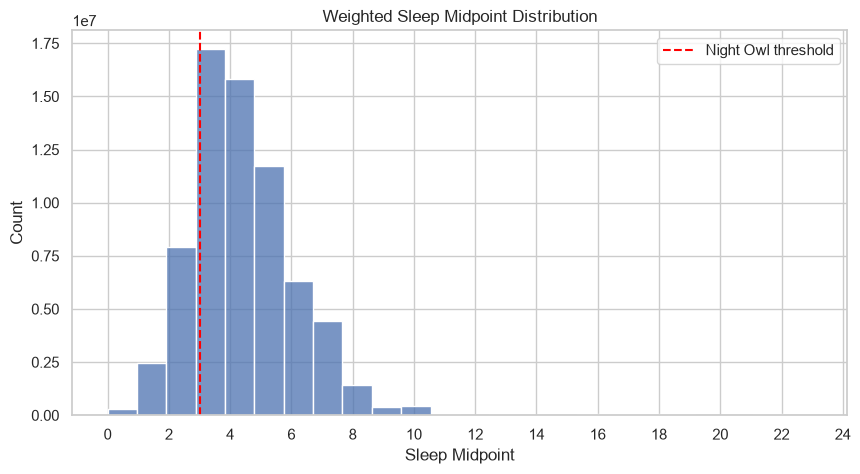

In [33]:

valid = df["Sleep_Midpoint"].notna() & df["WTINT2YR"].gt(0)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df.loc[valid],
    x="Sleep_Midpoint",
    weights="WTINT2YR",
    bins=24
)

plt.axvline(
    3,
    linestyle="--",
    color="red",
    label="Night Owl threshold"
)

plt.xticks(range(0, 25, 2))
plt.xlabel("Sleep Midpoint")
plt.title("Weighted Sleep Midpoint Distribution")
plt.legend()

plt.show()


In [34]:

save_results(
    {
        "summary": compensation["summary"],
        "gender": gender_compensation,
        "education": education_compensation,
        "sleep_statistics": sleep_stats
    },
    OUTPUT_PATH / "tables",
    "compensation"
)

save_results(
    {
        "summary": night_owls["summary"],
        "gender": gender_owls,
        "education": education_owls
    },
    OUTPUT_PATH / "tables",
    "night_owls"
)

print("Weighted analysis results saved.")


Weighted analysis results saved.


بریم برای احتمالات بیشتر 

In [35]:
import importlib
import numpy as np
from scipy import stats
import src.sleep_probability as sp
importlib.reload(sp)

<module 'src.sleep_probability' from 'd:\\Study\\SUT-CS\\Books\\آمار\\project\\phase-2\\src\\sleep_probability.py'>

In [36]:
result_education = sp.night_owl_education_distribution(df)

print("Sample size:", result_education["sample_size"])

print("\nWeighted joint frequencies:")
display(result_education["weighted_counts"])

print("\nWeighted joint probabilities:")
display(result_education["joint_probabilities"])

print("\nRaw counts:")
display(result_education["raw_counts"])

Sample size: 1608

Weighted joint frequencies:


DMDEDUC2,1.0,2.0,3.0,4.0,5.0
Night_Owl,,,,,
Night Owl,868358.491768,3.666007e+06,1.625167e+07,1.828364e+07,1.893431e+07
Not Night Owl,193923.058836,2.659118e+05,3.025777e+06,2.861409e+06,4.441679e+06



Weighted joint probabilities:


DMDEDUC2,1.0,2.0,3.0,4.0,5.0
Night_Owl,,,,,
Night Owl,0.012623,0.053291,0.236241,0.265779,0.275237
Not Night Owl,0.002819,0.003865,0.043984,0.041595,0.064566



Raw counts:


DMDEDUC2,1.0,2.0,3.0,4.0,5.0
Night_Owl,,,,,
Night Owl,19,104,322,457,452
Not Night Owl,6,12,56,75,105


In [37]:
import numpy as np

df["Night_Owl"] = np.where(
    df["Sleep_Midpoint"].notna(),
    (df["Sleep_Midpoint"] >= 5).astype(int),
    np.nan
)

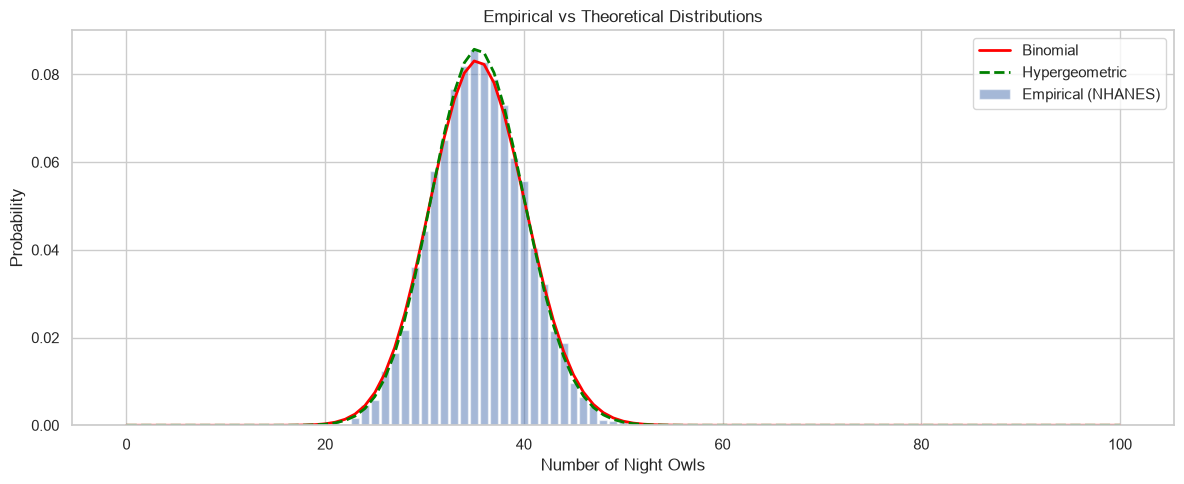

=== Sampling Information ===
Population size: 1609
Sample size: 100
Repetitions: 5000
Night Owl probability: 0.35425730267246736

=== Mean and Variance ===
Empirical mean: 35.416
Binomial mean: 35.425730267246735
Empirical variance: 21.417344
Binomial variance: 22.87590661756952

=== Binomial Goodness of Fit ===
{'chi_square': 26.046301942221003, 'p_value': 0.623015337220869, 'degrees_of_freedom': 29, 'groups': 30}

=== Hypergeometric Goodness of Fit ===
{'chi_square': 15.981252754455285, 'p_value': 0.9660960996183455, 'degrees_of_freedom': 28, 'groups': 29}

=== Total Variation Distance ===
Empirical vs Binomial: 0.02099341743274366
Empirical vs Hypergeometric: 0.017204149063727338


In [38]:

# 1. Generate real samples
sample_result = sp.sample_night_owl_counts(
    df,
    n=100,
    repetitions=5000,
    seed=42
)

# 2. Test distribution fit
result = sp.analyze_binomial_fit(sample_result)

# 3. Plot distributions
distribution = result["distribution"]

plt.figure(figsize=(12, 5))

plt.bar(
    distribution["Number_of_Night_Owls"],
    distribution["Empirical_Probability"],
    width=0.8,
    alpha=0.5,
    label="Empirical (NHANES)"
)

plt.plot(
    distribution["Number_of_Night_Owls"],
    distribution["Binomial_Probability"],
    color="red",
    linewidth=2,
    label="Binomial"
)

plt.plot(
    distribution["Number_of_Night_Owls"],
    distribution["Hypergeometric_Probability"],
    color="green",
    linestyle="--",
    linewidth=2,
    label="Hypergeometric"
)

plt.xlabel("Number of Night Owls")
plt.ylabel("Probability")
plt.title("Empirical vs Theoretical Distributions")
plt.legend()
plt.tight_layout()
plt.show()

# 4. Print results
print("=== Sampling Information ===")
print("Population size:", sample_result["N"])
print("Sample size:", sample_result["n"])
print("Repetitions:", len(sample_result["counts"]))
print("Night Owl probability:", sample_result["p"])

print("\n=== Mean and Variance ===")
print("Empirical mean:", result["empirical_mean"])
print("Binomial mean:", result["binomial_mean"])
print("Empirical variance:", result["empirical_variance"])
print("Binomial variance:", result["binomial_variance"])

print("\n=== Binomial Goodness of Fit ===")
print(result["binomial_test"])

print("\n=== Hypergeometric Goodness of Fit ===")
print(result["hypergeometric_test"])

# 5. Compare distribution distances
empirical = distribution["Empirical_Probability"].to_numpy()
binomial = distribution["Binomial_Probability"].to_numpy()
hypergeometric = distribution["Hypergeometric_Probability"].to_numpy()

print("\n=== Total Variation Distance ===")
print("Empirical vs Binomial:",
      0.5 * np.abs(empirical - binomial).sum())

print("Empirical vs Hypergeometric:",
      0.5 * np.abs(empirical - hypergeometric).sum())

mean: 7.831072179394363
variance: 2.113808078157548
std: 1.4538941083027843
skewness: 0.06566314989574194
excess_kurtosis: 1.3823202369661285
sample_size: 1609


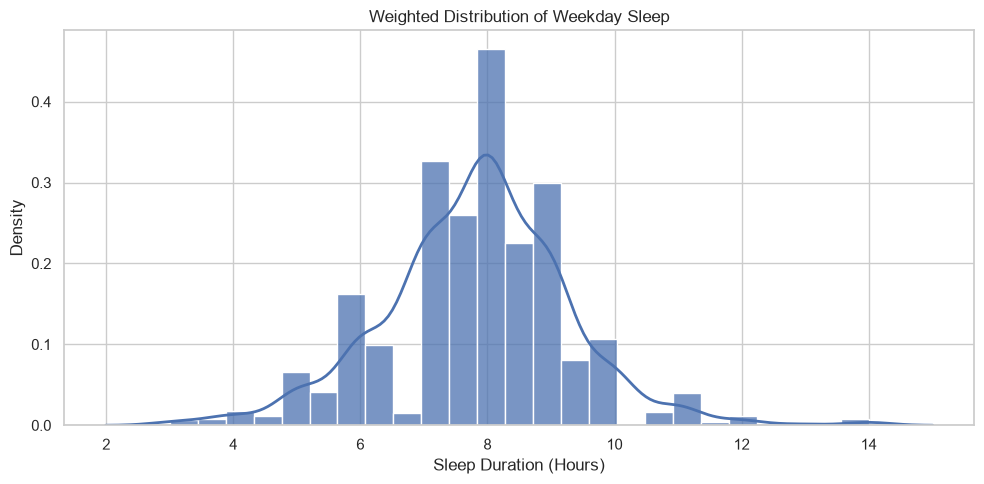

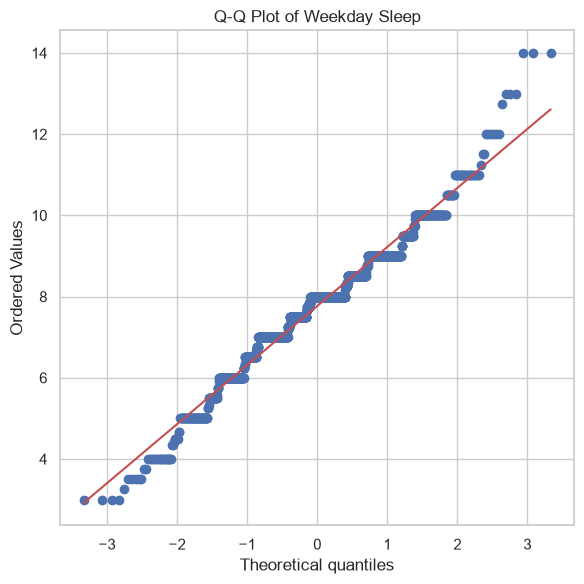

In [39]:
normal_result = sp.analyze_weekday_sleep_distribution(df)

for key in [
    "mean",
    "variance",
    "std",
    "skewness",
    "excess_kurtosis",
    "sample_size"
]:
    print(f"{key}: {normal_result[key]}")

    data = normal_result["data"]

plt.figure(figsize=(10, 5))

sns.histplot(
    data=data,
    x="Weekday_Sleep",
    weights="WTINT2YR",
    stat="density",
    bins=25,
    kde=False
)

sns.kdeplot(
    data=data,
    x="Weekday_Sleep",
    weights="WTINT2YR",
    linewidth=2
)

plt.title("Weighted Distribution of Weekday Sleep")
plt.xlabel("Sleep Duration (Hours)")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 6))

stats.probplot(
    data["Weekday_Sleep"],
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Weekday Sleep")
plt.tight_layout()
plt.show()

In [40]:
age_result = sp.expected_weekday_sleep_by_age(df)

display(age_result)

,Age_Group,Weighted_Mean_Sleep,Weighted_Variance,Raw_Count,Weighted_Count
0,20-24,8.074961,2.457317,399,2.039053e+07
1,25-29,7.778958,1.772322,492,2.134171e+07
2,30-34,7.649368,2.025174,611,2.308797e+07


منطقیه چون توقع داریم توی سنین 25 تا 30 سالگی ملت زندگیشون به یه ثباتی رسیده باشه. و مثلا دانشجو شب امتحانی بدبخت نباشن . 

Weighted joint frequencies:


Night_Owl,Night Owl,Not Night Owl
Savings,,
Has Savings,3.176321e+07,4.470258e+06
No Savings,1.727959e+07,4.263195e+06



Weighted joint probabilities:


Night_Owl,Night Owl,Not Night Owl
Savings,,
Has Savings,0.549762,0.077372
No Savings,0.299078,0.073788



Conditional probabilities:
P_Night_Owl_given_Savings: 0.8766262482220983
P_Night_Owl_given_No_Savings: 0.8021056615149074
P_Savings_given_Night_Owl: 0.6476630287135954
P_Savings_given_Not_Night_Owl: 0.5118545963262459


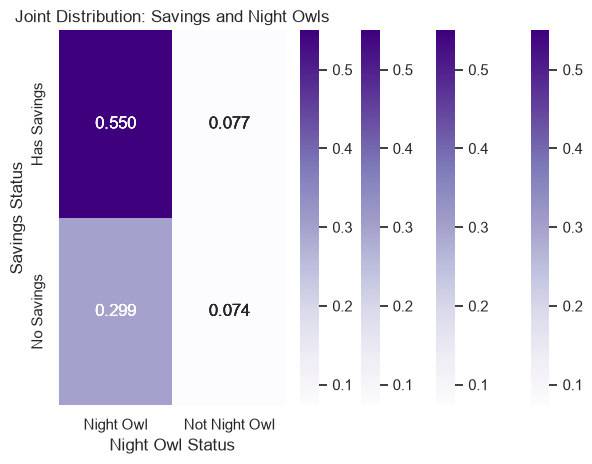

In [41]:
bayes_result = sp.analyze_savings_bayes(df)

print("Weighted joint frequencies:")
display(bayes_result["weighted_counts"])

print("\nWeighted joint probabilities:")
display(bayes_result["joint_probabilities"])

print("\nConditional probabilities:")

for key in [
    "P_Night_Owl_given_Savings",
    "P_Night_Owl_given_No_Savings",
    "P_Savings_given_Night_Owl",
    "P_Savings_given_Not_Night_Owl"
]:
    print(f"{key}: {bayes_result[key]}")

    sns.heatmap(
    bayes_result["joint_probabilities"],
    annot=True,
    fmt=".3f",
    cmap="Purples"
)

plt.title("Joint Distribution: Savings and Night Owls")
plt.xlabel("Night Owl Status")
plt.ylabel("Savings Status")

plt.tight_layout()
plt.show()

نمیتونیم نتیجه بگیریم که حغد ها پس انداز بیشتری دارن، شاید توزیع جامعه طوریه که کلا کسایی که پس اندزا دارن بیشترن !کما اینکه احتمال شرطی هاشونم تفاوت خاصی نداشت. 

این سوالم خیلی جالبه! بیشتر آدم ها ساعت خوابشون رو رند کردن حالا یا به یک ساعت کامل یا به نیم ساعت یه تعداد اندکی اینکار و نکردن . حالا میخام ببینم آیا اینکه کسی ساعت های گفته شده شو توی نظر سنجی رند کرده باشه مستقل از اینه که زن باشه یا مرد یا نه ؟ 


In [42]:
independence_result = (
    sp.analyze_sleep_rounding_independence(df)
)

print("Valid sample size:",
      independence_result["sample_size"])

print("\nWeighted joint frequencies:")
display(independence_result["weighted_counts"])

print("\nWeighted joint probabilities:")
display(independence_result["joint_probabilities"])

print("\nIndependence comparison:")
display(independence_result["independence_comparison"])

print("\nRaw counts:")
display(independence_result["raw_counts"])

Valid sample size: 1609

Weighted joint frequencies:


Unrounded,Rounded,Unrounded
Gender,,
Female,3.122742e+07,3.186995e+06
Male,3.185384e+07,2.541021e+06



Weighted joint probabilities:


Unrounded,Rounded,Unrounded
Gender,,
Female,0.453826,0.046316
Male,0.462929,0.036928



Independence comparison:


,Gender,P_Gender,P_Unrounded_Given_Gender,P_Joint,P_Product,Difference
0,Female,0.500142,0.092606,0.046316,0.041634,0.004682
1,Male,0.499858,0.073878,0.036928,0.041611,-0.004682



Raw counts:


Unrounded,False,True
Gender,,
Female,808,88
Male,654,59


احتمال اشتراکشون برابر با احتمال حاصل ضربشون نیست پس مستقل نیستند ولی وایستگی کمه ! زن ها کمتر از مرد ها رند کردن .